<a href="https://colab.research.google.com/github/ascot119-rgb/Alex-s-Projects/blob/main/Image_Classification_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard MLP Networks

Time: 494.7900706920009 Seconds
Trainable Parameters: 820,874
Training Loss: 1.0311425
Training Accuracy 0.6313199996948242
Validation Accuracy 0.5206999778747559
Validation Precision 0.5586263881471405
Validation Recall 0.5207


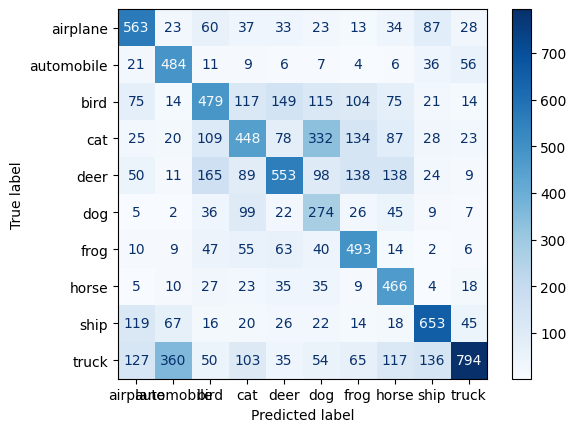

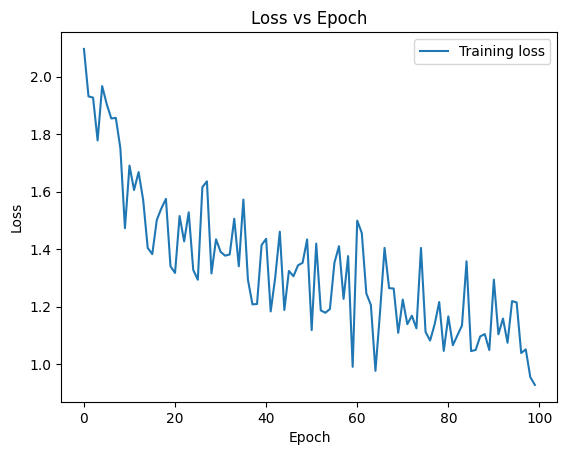

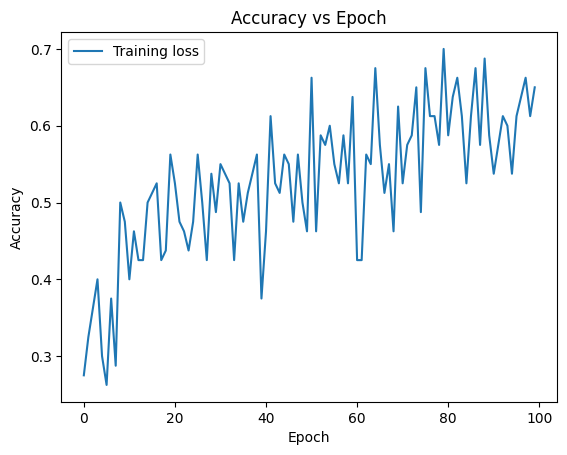

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.275   2.09697
      1      0.325   1.93173
      2      0.3625  1.92744
      3      0.4     1.77836
      4      0.3     1.96753
      5      0.2625  1.90463
      6      0.375   1.85482
      7      0.2875  1.85689
      8      0.5     1.75053
      9      0.475   1.47288
     10      0.4     1.69071
     11      0.4625  1.60583
     12      0.425   1.66823
     13      0.425   1.57154
     14      0.5     1.40421
     15      0.5125  1.38251
     16      0.525   1.50182
     17      0.425   1.54193
     18      0.4375  1.57481
     19      0.5625  1.34022
     20      0.525   1.31706
     21      0.475   1.51504
     22      0.4625  1.42704
     23      0.4375  1.52806
     24      0.475   1.32736
     25      0.5625  1.29345
     26      0.5     1.61595
     27      0.425   1.6359
     28      0.5375  1.31524
     29      0.4875  1.43426
     30      0.55    1.39039
     31      0.5375  1.37726
     32      

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

Time: 931.0095446960004 Seconds
Trainable Parameters: 1,707,274
Training Loss: 0.9540335
Training Accuracy 0.6587799787521362
Validation Accuracy 0.529699981212616
Validation Precision 0.5666779797489178
Validation Recall 0.5297


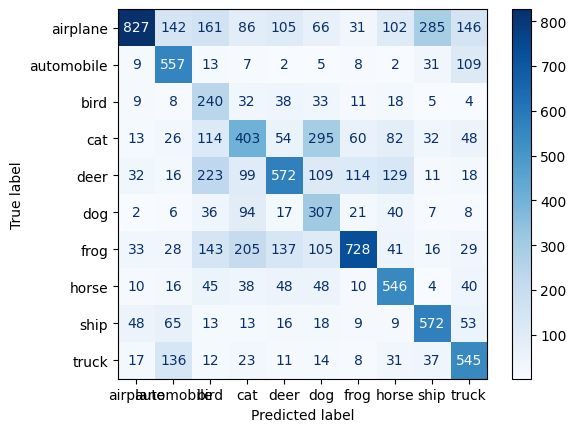

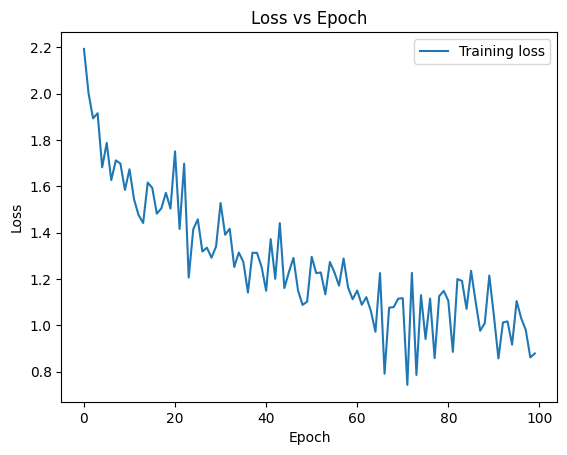

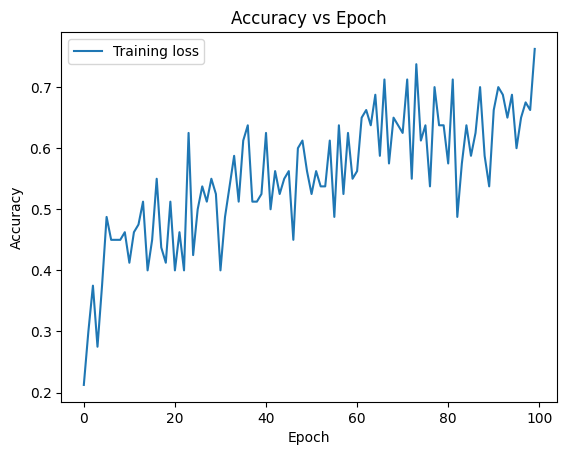

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.2125  2.19347
      1      0.3     2.00341
      2      0.375   1.89349
      3      0.275   1.91595
      4      0.375   1.68237
      5      0.4875  1.7877
      6      0.45    1.62727
      7      0.45    1.71229
      8      0.45    1.69867
      9      0.4625  1.58475
     10      0.4125  1.67421
     11      0.4625  1.54426
     12      0.475   1.47606
     13      0.5125  1.44212
     14      0.4     1.61667
     15      0.45    1.59353
     16      0.55    1.48217
     17      0.4375  1.50563
     18      0.4125  1.57245
     19      0.5125  1.50426
     20      0.4     1.75139
     21      0.4625  1.41624
     22      0.4     1.69822
     23      0.625   1.20659
     24      0.425   1.41524
     25      0.5     1.45819
     26      0.5375  1.31894
     27      0.5125  1.33562
     28      0.55    1.29228
     29      0.525   1.34007
     30      0.4     1.52834
     31      0.4875  1.39134
     32      

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

# Deepened MLP Networks

Time: 542.0558674339991 Seconds
Trainable Parameters: 886,794
Training Loss: 0.9493242
Training Accuracy 0.6511200070381165
Validation Accuracy 0.5153999924659729
Validation Precision 0.54784891822153
Validation Recall 0.5154


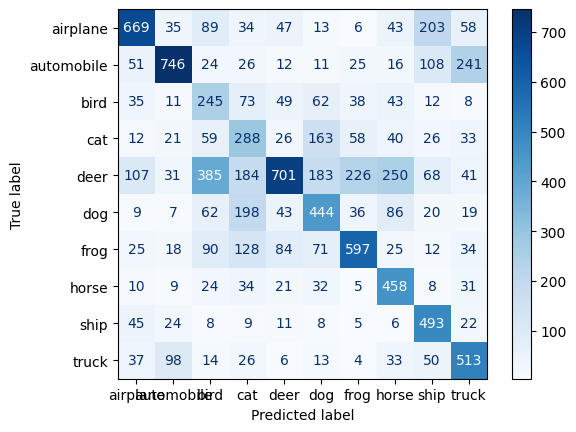

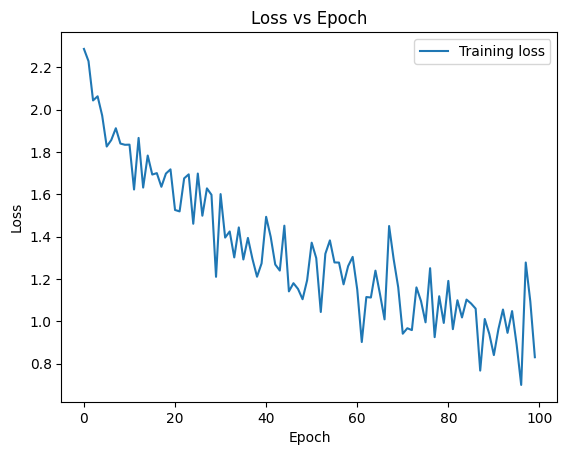

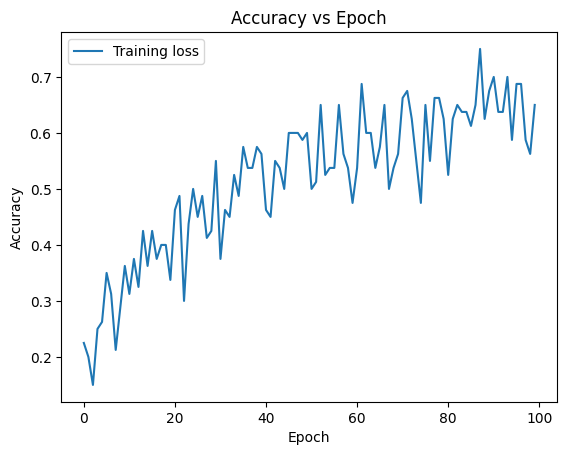

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.225   2.28717
      1      0.2     2.22928
      2      0.15    2.04371
      3      0.25    2.06331
      4      0.2625  1.97254
      5      0.35    1.82593
      6      0.3125  1.8567
      7      0.2125  1.91235
      8      0.2875  1.84002
      9      0.3625  1.83412
     10      0.3125  1.83481
     11      0.375   1.62283
     12      0.325   1.86662
     13      0.425   1.63198
     14      0.3625  1.78342
     15      0.425   1.6935
     16      0.375   1.70019
     17      0.4     1.63569
     18      0.4     1.69819
     19      0.3375  1.71805
     20      0.4625  1.52607
     21      0.4875  1.51933
     22      0.3     1.67554
     23      0.4375  1.69441
     24      0.5     1.46096
     25      0.45    1.69825
     26      0.4875  1.499
     27      0.4125  1.62823
     28      0.425   1.59777
     29      0.55    1.21018
     30      0.375   1.60115
     31      0.4625  1.3956
     32      0.45

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

Time: 1540.4709113380013 Seconds
Trainable Parameters: 2,497,738
Training Loss: 2.3025823
Training Accuracy 0.10000000149011612
Validation Accuracy 0.10000000149011612
Validation Precision 0.01
Validation Recall 0.1


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


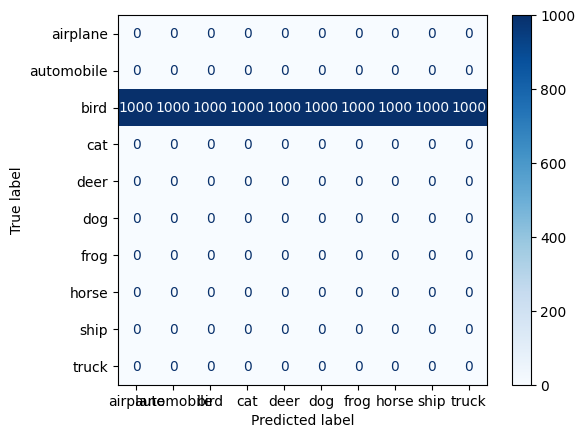

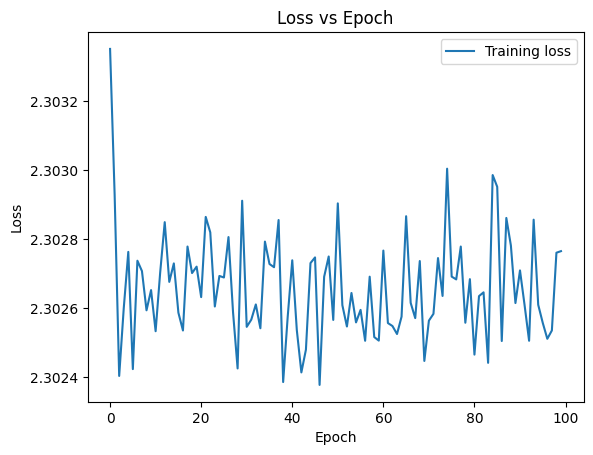

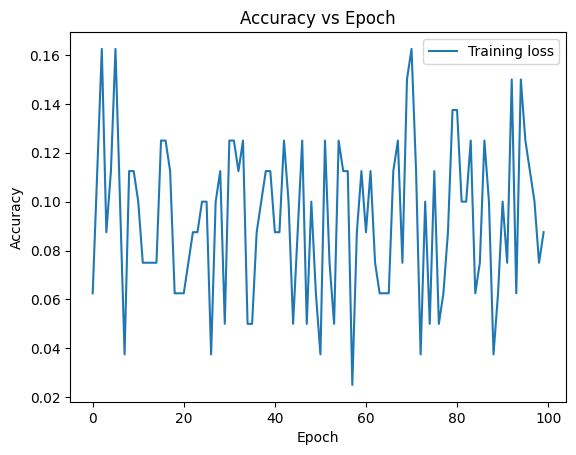

  Epoch    Accuracy     Loss
-------  ----------  -------
      0      0.0625  2.30335
      1      0.1125  2.30293
      2      0.1625  2.3024
      3      0.0875  2.3026
      4      0.1125  2.30276
      5      0.1625  2.30242
      6      0.1     2.30274
      7      0.0375  2.30271
      8      0.1125  2.30259
      9      0.1125  2.30265
     10      0.1     2.30253
     11      0.075   2.3027
     12      0.075   2.30285
     13      0.075   2.30268
     14      0.075   2.30273
     15      0.125   2.30259
     16      0.125   2.30254
     17      0.1125  2.30278
     18      0.0625  2.3027
     19      0.0625  2.30272
     20      0.0625  2.30263
     21      0.075   2.30286
     22      0.0875  2.30282
     23      0.0875  2.30261
     24      0.1     2.30269
     25      0.1     2.30269
     26      0.0375  2.30281
     27      0.1     2.30259
     28      0.1125  2.30243
     29      0.05    2.30291
     30      0.125   2.30255
     31      0.125   2.30257
     32      0.112

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.ReLU(),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 192),
    nn.ReLU(),
    nn.Linear(192, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

# Different Activation Functions

Time: 495.72917922200213 Seconds
Trainable Parameters: 820,874
Training Loss: 1.7295725
Training Accuracy 0.38148000836372375
Validation Accuracy 0.3815999925136566
Validation Precision 0.37410110787225564
Validation Recall 0.3816


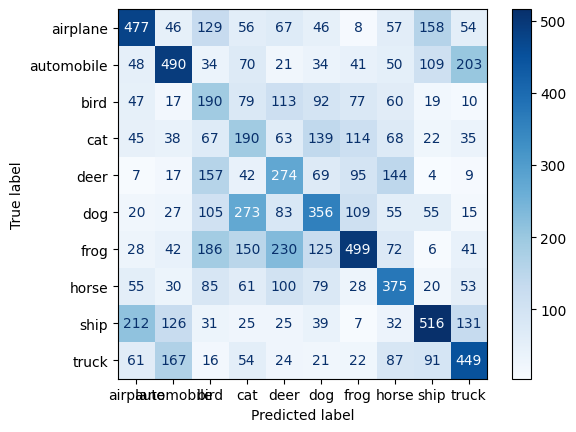

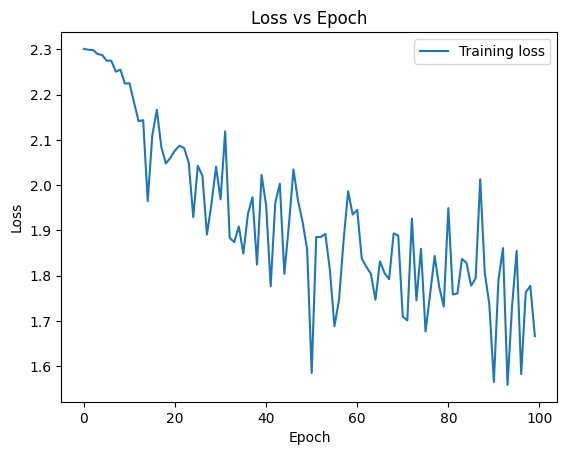

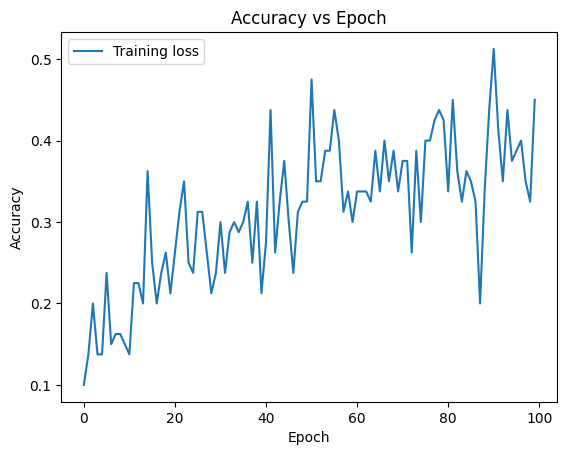

  Epoch    Accuracy     Loss
-------  ----------  -------
      0      0.1     2.30108
      1      0.1375  2.29917
      2      0.2     2.29853
      3      0.1375  2.28985
      4      0.1375  2.28769
      5      0.2375  2.27496
      6      0.15    2.27511
      7      0.1625  2.2508
      8      0.1625  2.25528
      9      0.15    2.22456
     10      0.1375  2.22521
     11      0.225   2.18269
     12      0.225   2.14151
     13      0.2     2.14367
     14      0.3625  1.96472
     15      0.25    2.10948
     16      0.2     2.16658
     17      0.2375  2.08379
     18      0.2625  2.04791
     19      0.2125  2.06095
     20      0.2625  2.07689
     21      0.3125  2.08711
     22      0.35    2.08189
     23      0.25    2.04996
     24      0.2375  1.92942
     25      0.3125  2.04265
     26      0.3125  2.02107
     27      0.2625  1.89077
     28      0.2125  1.95858
     29      0.2375  2.04078
     30      0.3     1.96856
     31      0.2375  2.11866
     32      0.

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.Sigmoid(),
    nn.Linear(256, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)


Time: 495.6458686980004 Seconds
Trainable Parameters: 820,874
Training Loss: 1.1121061
Training Accuracy 0.6092399954795837
Validation Accuracy 0.5188000202178955
Validation Precision 0.5425891068740786
Validation Recall 0.5187999999999999


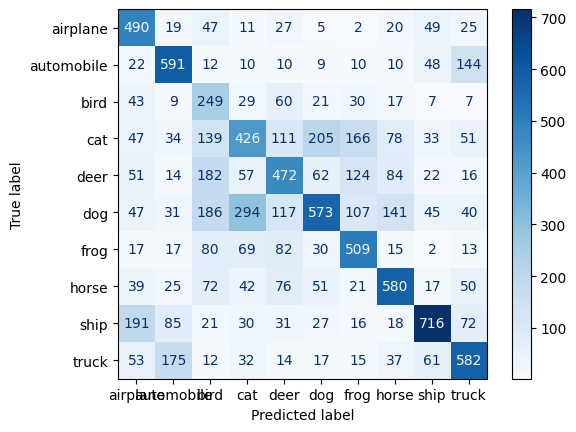

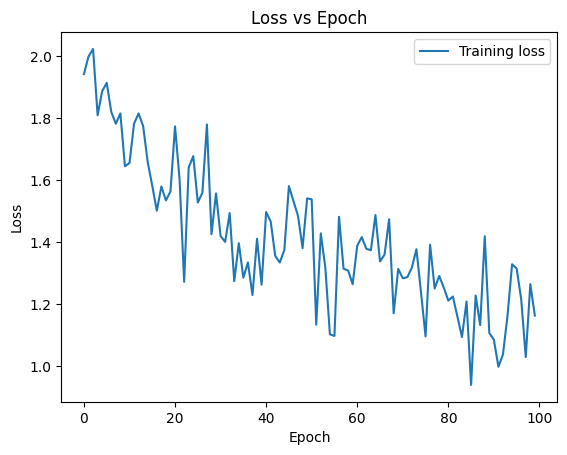

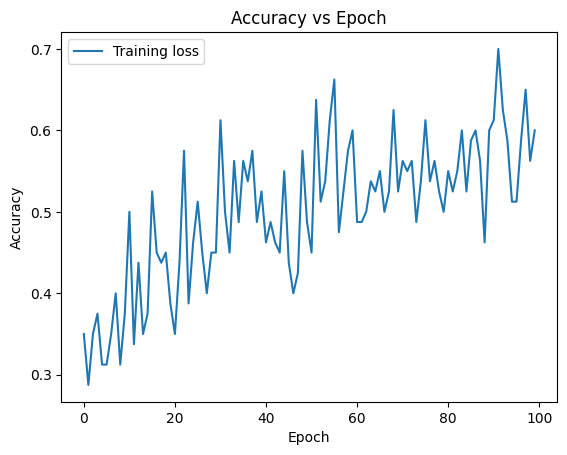

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.35    1.94231
      1      0.2875  1.99898
      2      0.35    2.02348
      3      0.375   1.80932
      4      0.3125  1.88696
      5      0.3125  1.91392
      6      0.35    1.82003
      7      0.4     1.78198
      8      0.3125  1.81524
      9      0.375   1.64452
     10      0.5     1.65525
     11      0.3375  1.78237
     12      0.4375  1.81536
     13      0.35    1.77412
     14      0.375   1.65766
     15      0.525   1.58147
     16      0.45    1.50113
     17      0.4375  1.57942
     18      0.45    1.53449
     19      0.3875  1.56396
     20      0.35    1.77353
     21      0.4375  1.60114
     22      0.575   1.2717
     23      0.3875  1.64108
     24      0.4625  1.67741
     25      0.5125  1.52766
     26      0.45    1.55897
     27      0.4     1.77951
     28      0.45    1.42535
     29      0.45    1.55697
     30      0.6125  1.41944
     31      0.5     1.40046
     32      

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.Tanh(),
    nn.Linear(256, 128),
    nn.Tanh(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(pred_val.detach().numpy()),
    labels_val,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)